# 10 - Feature Importance


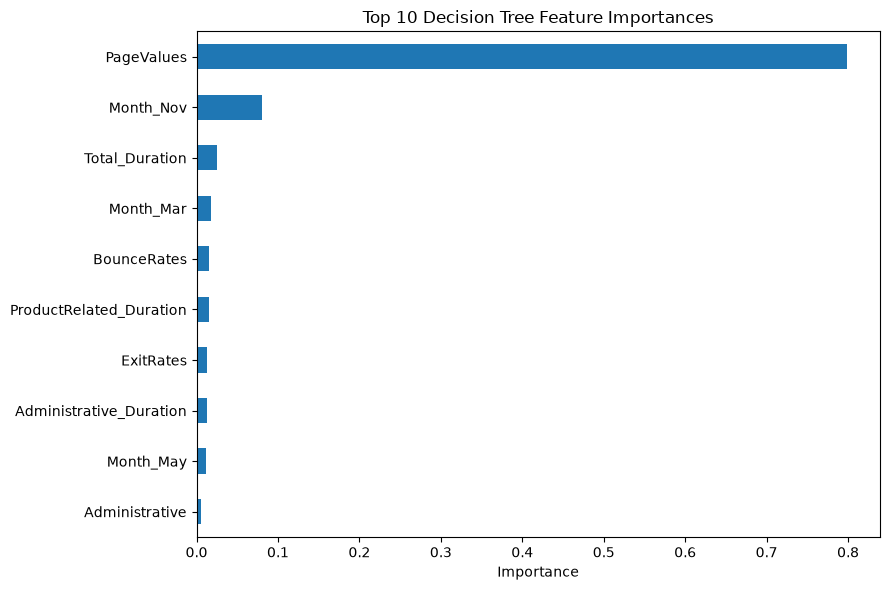

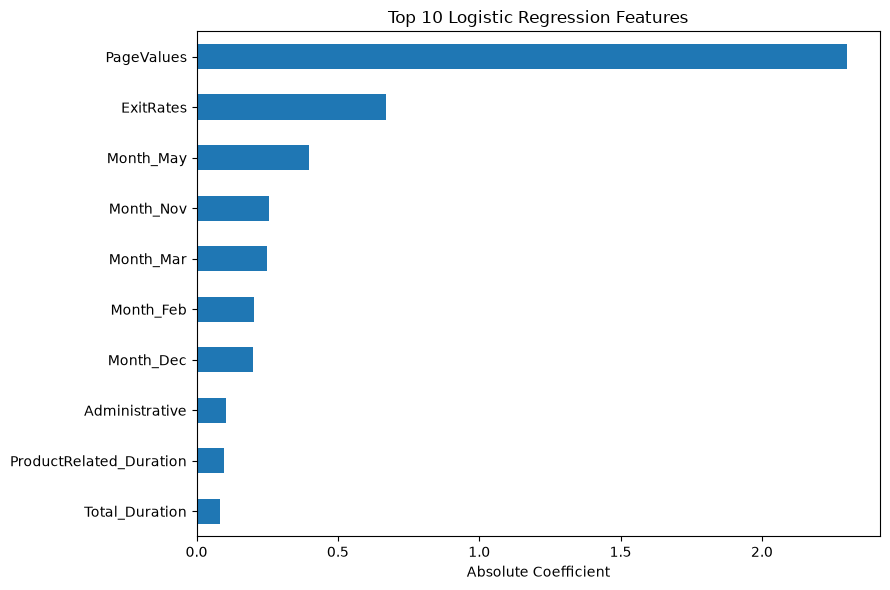

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('online_shoppers_intention.csv')
df = df.drop_duplicates().copy()
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)

df['Total_Pages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['Total_Duration'] = (
    df['Administrative_Duration'] +
    df['Informational_Duration'] +
    df['ProductRelated_Duration']
)

df = pd.get_dummies(
    df,
    columns=['Month', 'VisitorType'],
    drop_first=True,
    dtype=int
)

X = df.drop('Revenue', axis=1)
y = df['Revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import numpy as np

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

k_values = list(range(1, 22, 2))
knn_scores = [
    cross_val_score(
        KNeighborsClassifier(n_neighbors=k),
        X_train_s, y_train, cv=5, scoring='f1'
    ).mean()
    for k in k_values
]
best_k = k_values[np.argmax(knn_scores)]

depth_values = [3, 5, 10, 15, 20, None]
dt_scores = [
    cross_val_score(
        DecisionTreeClassifier(max_depth=d, random_state=42),
        X_train, y_train, cv=5, scoring='f1'
    ).mean()
    for d in depth_values
]
best_depth = depth_values[np.argmax(dt_scores)]


import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=best_depth,
    class_weight='balanced',
    random_state=42
)
dt_model.fit(X_train, y_train)

dt_imp = pd.Series(
    dt_model.feature_importances_,
    index=X.columns
).nlargest(10).sort_values()

plt.figure(figsize=(9, 6))
dt_imp.plot(kind='barh')
plt.title('Top 10 Decision Tree Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train_s, y_train)

lr_imp = pd.Series(
    lr_model.coef_[0],
    index=X.columns
).abs().nlargest(10).sort_values()

plt.figure(figsize=(9, 6))
lr_imp.plot(kind='barh')
plt.title('Top 10 Logistic Regression Features')
plt.xlabel('Absolute Coefficient')
plt.tight_layout()
plt.show()
